# Python для ML: массивы вместо циклов

ФПМИ.Будущее · ИИ · Прекурс · Занятие 1

NumPy позволяет описать операцию сразу над всем массивом — без ручного перебора элементов.

В задачах ML данные часто выглядят как таблица: объекты по строкам, признаки по столбцам. Сегодня будем выбирать нужные данные и считать по ним без циклов.

Для многомерного массива достаточно помнить, что хранится на каждой оси, и следить за изменением `shape`.


## 1. Одна операция для всего массива

Прибавим один балл каждому ученику. Сначала — обычный цикл, затем — операция NumPy.


In [1]:
import numpy as np

scores_list = [4, 6, 8]

with_loop = []
for score in scores_list:
    with_loop.append(score + 1)

scores = np.array(scores_list)
with_numpy = scores + 1

print("Цикл:", with_loop)
print("NumPy:", with_numpy)


Цикл: [5, 7, 9]
NumPy: [5 7 9]


In [2]:
# Список повторяется, а NumPy умножает каждое число.
print("Список × 2:", scores_list * 2)
print("Массив × 2:", scores * 2)


Список × 2: [4, 6, 8, 4, 6, 8]
Массив × 2: [ 8 12 16]


In [3]:
# Короткое сравнение скорости на большом массиве.
large_list = list(range(100_000))
large_array = np.arange(100_000)

print("Python — возведение в квадрат:")
%timeit -n 5 -r 3 [x ** 2 for x in large_list]
print("NumPy — возведение в квадрат:")
%timeit -n 5 -r 3 large_array ** 2


Python — возведение в квадрат:
7.67 ms ± 500 µs per loop (mean ± std. dev. of 3 runs, 5 loops each)
NumPy — возведение в квадрат:
76.1 µs ± 15.7 µs per loop (mean ± std. dev. of 3 runs, 5 loops each)


> Сегодня важнее не конкретное ускорение, а способ мышления: операция применяется к массиву целиком.


## 2. `shape`: читаем структуру данных

Каждая строка массива `X` — ученик. Каждый столбец — признак. В нашем примере признаки — это результаты по предметам.


In [4]:
# Строки: Аня, Боря, Вика.
# Столбцы: Python, математика.
X = np.array([
    [4, 8],
    [6, 2],
    [8, 5],
])

print(X)


[[4 8]
 [6 2]
 [8 5]]


In [5]:
for i in X:

    print(i)

[4 8]
[6 2]
[8 5]


In [ ]:
print("Форма X:", X.shape)


Форма X: (3, 2)


![Форма двумерного массива: ученики и предметы](attachment:shape-2d.png)


## 3. Выбираем нужную часть массива

Для двумерного массива используем запись `X[строки, столбцы]`. Индексы начинаются с `0`, а `:` без границ оставляет все элементы этой оси.

**До запуска:** попробуйте назвать смысл и форму каждого результата.


In [ ]:
print("X[0]:", X[0])
print("shape:", X[0].shape)
print()
print("X[:, 0]:", X[:, 0])
print("shape:", X[:, 0].shape)
print()
print("X[0, 1]:", X[0, 1])
print("shape:", X[0, 1].shape)


X[0]: [4 8]
shape: (2,)

X[:, 0]: [4 6 8]
shape: (3,)

X[0, 1]: 8
shape: ()


Срез `:2` означает индексы `0` и `1`. Правая граница `2` в результат не входит.


In [ ]:
first_two_students = X[:2, :]
print("Первые два ученика:")
print(first_two_students)
print("Форма:", first_two_students.shape)


Первые два ученика:
[[4 8]
 [6 2]]
Форма: (2, 2)


## 4. Булева маска: фильтр без цикла

Сравнение выполняется отдельно для каждого элемента и создаёт массив из `True` и `False`.


In [ ]:
python_scores = X[:, 0]
mask = python_scores >= 6

print("Маска:", mask)


Маска: [False  True  True]


In [ ]:
print("Подходящие баллы по Python:", python_scores[mask])
print("Все предметы выбранных учеников:")
print(X[mask])


Подходящие баллы по Python: [6 8]
Все предметы выбранных учеников:
[[6 2]
 [8 5]]


В вычислениях `False` ведёт себя как `0`, а `True` — как `1`. Поэтому:

- `mask.sum()` — количество подходящих элементов;
- `mask.mean()` — доля подходящих элементов.


In [ ]:
print("Маска как числа:", mask.astype(int))
print("Количество подходящих учеников:", mask.sum())
print("Доля подходящих учеников:", mask.mean())


Маска как числа: [0 1 1]
Количество подходящих учеников: 2
Доля подходящих учеников: 0.6666666666666666


### Мини-задача 1. Фильтр

Выберите из `X` строки учеников, у которых балл по Python строго больше `5`.

Ожидаемая форма ответа: `(2, 2)`.

Заполните следующую ячейку, затем запустите проверку под ней. `assert` проверяет условие, а `np.array_equal` сравнивает массивы поэлементно.


In [ ]:
selected_students = X[X[:, 0] > 5]


In [ ]:
assert selected_students.shape == (2, 2)
assert np.array_equal(selected_students, np.array([[6, 2], [8, 5]]))

print("Мини-задача 1: тесты пройдены")


Мини-задача 1: тесты пройдены


<details>
<summary>Показать решение</summary>

```python
selected_students = X[X[:, 0] > 5]
```

</details>


## 5. Поэлементные операции

Одна и та же операция применяется ко всем элементам массива.


In [ ]:
print("X + 1:")
print(X + 1)
print()
print("X * 2:")
print(X * 2)
print()
print("X >= 6:")
print(X >= 6)


X + 1:
[[5 9]
 [7 3]
 [9 6]]

X * 2:
[[ 8 16]
 [12  4]
 [16 10]]

X >= 6:
[[False  True]
 [ True False]
 [ True False]]


## 6. Агрегаты и `axis`

`mean` вычисляет среднее, `sum` — сумму, `argmax` — индекс максимума. По умолчанию указанная в `axis` ось исчезает из формы результата.


![Как axis меняет форму результата](attachment:axis.png)


In [ ]:
# Исчезают ученики: остаётся одно среднее на предмет.
mean_per_subject = X.mean(axis=0)

# Исчезают предметы: остаётся одна сумма на ученика.
sum_per_student = X.sum(axis=1)

print("Среднее по предметам:", mean_per_subject)
print("Форма:", mean_per_subject.shape)
print()
print("Сумма по ученикам:", sum_per_student)
print("Форма:", sum_per_student.shape)


Среднее по предметам: [6. 5.]
Форма: (2,)

Сумма по ученикам: [12  8 13]
Форма: (3,)


`argmax` возвращает **индекс** максимального элемента, а не само значение. Индексы начинаются с `0`; при одинаковых максимумах возвращается первый индекс.


In [ ]:
names = np.array(["Аня", "Боря", "Вика"])
best_student_index = X.argmax(axis=0)

print("Предметы: Python, математика")
print("Индексы лучших учеников:", best_student_index)
print("Имена:", names[best_student_index])


Предметы: Python, математика
Индексы лучших учеников: [2 0]
Имена: ['Вика' 'Аня']


### Мини-задача 2. Среднее по строкам

Найдите средний балл каждого ученика по двум предметам.

Ожидаемая форма ответа: `(3,)`.

Заполните ячейку и запустите проверку. `np.allclose` сравнивает числовые массивы с учётом небольших погрешностей вычислений.


In [ ]:
# mean_per_student = (X[:, 0] + X[:, 1])/2
mean_per_student = X.mean(axis=1)

In [ ]:
assert mean_per_student.shape == (3,)
assert np.allclose(mean_per_student, np.array([6.0, 4.0, 6.5]))

print("Мини-задача 2: тесты пройдены")


Мини-задача 2: тесты пройдены


<details>
<summary>Показать решение</summary>

```python
mean_per_student = X.mean(axis=1)
```

</details>


## 7. Добавляем время: три оси

Теперь у каждого ученика есть результаты за четыре недели. Позиция оси зависит от конкретного массива:

- в `X` предметы находятся на `axis=1`;
- в `T` добавилось время, поэтому предметы находятся на `axis=2`.


In [ ]:
# Оси: ученик, неделя, предмет.
T = np.array([
    [[4, 8], [5, 8], [6, 9], [7, 9]],  # Аня
    [[6, 2], [6, 4], [7, 4], [8, 6]],  # Боря
    [[8, 5], [8, 6], [9, 7], [9, 8]],  # Вика
])

print("Форма T:", T.shape)


Форма T: (3, 4, 2)


![Трёхмерный массив: ученик, неделя, предмет](attachment:shape-3d.png)


**До запуска:** какая форма останется в каждом случае?


In [ ]:
print("T[:, 0, :].shape:", T[:, 0, :].shape) # (3, 2)
print("T[0, :, 0].shape:", T[0, :, 0].shape) # (4)
print("T.mean(axis=1).shape:", T.mean(axis=1).shape) # (3,4,2) -> (3, 2)


T[:, 0, :].shape: (3, 2)
T[0, :, 0].shape: (4,)
T.mean(axis=1).shape: (3, 2)


In [ ]:
print("T[:, 0, :]:")
print(T[:, 0, :])
print()
print("T[0, :, 0]:", T[0, :, 0])
print()
print("T.mean(axis=1):")
print(T.mean(axis=1))



T[:, 0, :]:
[[4 8]
 [6 2]
 [8 5]]

T[0, :, 0]: [4 5 6 7]

T.mean(axis=1):
[[5.5  8.5 ]
 [6.75 4.  ]
 [8.5  6.5 ]]
[4 5 6 7]


### Мини-задача 3. Среднее по времени

Для каждого ученика найдите средний балл по математике за четыре недели.

Ожидаемая форма ответа: `(3,)`.

Сначала выберите предмет, затем усредните по времени. Заполните ячейку и запустите проверку.


In [ ]:
math_mean_over_time = T[:,:,1].mean(axis=1)
print(math_mean_over_time)


[8.5 4.  6.5]


In [ ]:
assert math_mean_over_time.shape == (3,)
assert np.allclose(math_mean_over_time, np.array([8.5, 4.0, 6.5]))

print("Мини-задача 3: тесты пройдены")


Мини-задача 3: тесты пройдены


<details>
<summary>Показать решение</summary>

```python
math_mean_over_time = T[:, :, 1].mean(axis=1)
```

</details>


## 8. Строим график прямо из NumPy-массива

Возьмём историю баллов по Python. Её форма — `(3, 4)`: три ученика и четыре недели.


In [ ]:
import matplotlib.pyplot as plt

weeks = np.arange(1, T.shape[1] + 1)
python_history = T[:, :, 0]

print("Ученики × недели:", python_history.shape)
print("Недели × ученики после .T:", python_history.T.shape)


print(T.shape[1])


Ученики × недели: (3, 4)
Недели × ученики после .T: (4, 3)
4


`plt.plot(x, y)` ожидает, что первый размер `y` совпадает с длиной `x`.

У этой двумерной таблицы транспонирование `.T` меняет оси местами: `(3, 4)` превращается в `(4, 3)`:

- 4 строки соответствуют неделям;
- 3 столбца становятся тремя линиями на графике.


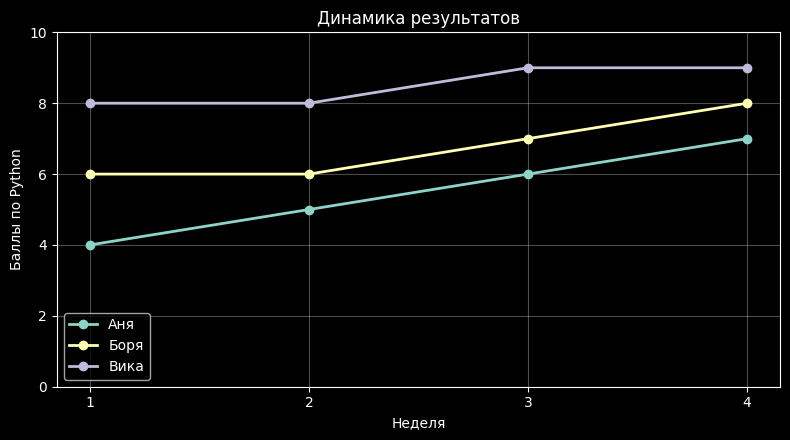

In [ ]:
# plt.style.use("dark_background")
plt.figure(figsize=(8, 4.5))
plt.plot(weeks, python_history.T, marker="o", linewidth=2)

plt.xticks(weeks)
plt.ylim(0, 10)
plt.xlabel("Неделя")
plt.ylabel("Баллы по Python")
plt.title("Динамика результатов")
plt.legend(names)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Где ещё используется NumPy


![Место NumPy среди pandas, matplotlib и scikit-learn](attachment:ecosystem.png)


## 9. Broadcasting и `keepdims`

Broadcasting позволяет совместить массивы разных, но подходящих форм. `keepdims=True` сохраняет исчезающую ось с длиной `1`.

Размеры сравниваются справа налево: каждая пара должна совпадать или содержать `1`. Недостающий размер считается равным `1`. Поэтому `(2,)` подходит к каждой строке массива `(3, 2)`.


![Broadcasting по столбцам и работа keepdims](attachment:broadcasting.png)


In [ ]:
means = X.mean(axis=0, keepdims=True)
centered = X - means

print("Средние по столбцам:", means)
print("Форма средних:", means.shape)
print()
print("После вычитания средних:")
print(centered)
print("Проверка средних по столбцам:", centered.mean(axis=0))


Средние по столбцам: [[6. 5.]]
Форма средних: (1, 2)

После вычитания средних:
[[-2.  3.]
 [ 0. -3.]
 [ 2.  0.]]
Проверка средних по столбцам: [0. 0.]


In [ ]:
time_means = T.mean(axis=1, keepdims=True) # (3, 4 , 2) -> (3, 1, 2)
centered_over_time = T - time_means

print("Исходный массив:", T.shape)
print("Среднее с keepdims:", time_means.shape)
print("Результат вычитания:", centered_over_time.shape)


Исходный массив: (3, 4, 2)
Среднее с keepdims: (3, 1, 2)
Результат вычитания: (3, 4, 2)


### Короткий пример из ML: стандартизация

Для каждого столбца независимо вычитаем среднее и делим на стандартное отклонение.

Стандартное отклонение (`std`) измеряет разброс значений вокруг среднего. Такое преобразование приводит признаки к сопоставимому масштабу: среднее становится близким к `0`, а `std` — к `1`.

В нашем примере оба столбца имеют ненулевой разброс. У постоянного столбца `std = 0`: делить на него нельзя, такой случай обрабатывают отдельно.


In [ ]:
means = X.mean(axis=0)
stds = X.std(axis=0)
X_standardized = (X - means) / stds

print("Стандартизованные признаки:")
print(X_standardized)


Стандартизованные признаки:
[[-1.22474487  1.22474487]
 [ 0.         -1.22474487]
 [ 1.22474487  0.        ]]


In [ ]:
# Проверяем результат: средние близки к 0, стандартные отклонения — к 1.
print("Средние по столбцам:", X_standardized.mean(axis=0))
print("Стандартные отклонения:", X_standardized.std(axis=0))


Средние по столбцам: [0. 0.]
Стандартные отклонения: [1. 1.]


## 10. Задача A1

Напишите функцию `above_average(a)`. На вход поступает непустой одномерный NumPy-массив оценок. Верните число от `0` до `1`: долю элементов, которые **строго больше среднего**.

Циклы использовать нельзя. Сначала напишите функцию, затем запустите ячейку с тестами. `np.isclose` сравнивает два числа с учётом небольших погрешностей.


In [ ]:
a1_scores = np.array([4, 5, 3, 5, 2, 4, 5, 3])

def above_average(a):
    a_mean = a.mean()
    is_above = a > a_mean
    return is_above.mean()


In [ ]:
assert np.isclose(above_average(np.array([4, 5, 3, 5, 2, 4, 5, 3])), 5 / 8)
assert np.isclose(above_average(np.array([7, 7, 7])), 0.0)
assert np.isclose(above_average(np.array([-3, -2, -1])), 1 / 3)

print("Тесты пройдены")


Тесты пройдены


In [ ]:
a = np.array([[[[[1]]]]])
a.shape

(1, 1, 1, 1, 1)

In [ ]:
int(a)

/var/folders/zd/hcrj29fn7ls56j4_qhhqys7r0000gn/T/ipykernel_87485/766485689.py:1: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  int(a)


1

In [ ]:
import numpy as np

def best_row(a):
    row_sums = a.sum(axis=1)
    return np.argmax(row_sums)

Проверим функцию на примерах:

**Пример 1:**
```python
a = np.array([[4, 8], [6, 2], [8, 5]])
# Суммы строк: [12, 8, 13]. Максимальная сумма 13 у строки с индексом 2.
assert best_row(a) == 2
print(f"Пример 1: {best_row(a)}")
```

**Пример 2:**
```python
a = np.array([[1, 2], [0, 3], [-1, 0]])
# Суммы строк: [3, 3, -1]. Максимальная сумма 3 у строк с индексами 0 и 1. Возвращаем наименьший индекс, т.е. 0.
assert best_row(a) == 0
print(f"Пример 2: {best_row(a)}")
```

In [ ]:
a = np.array([[4, 8], [6, 2], [8, 5]])
# Суммы строк: [12, 8, 13]. Максимальная сумма 13 у строки с индексом 2.
assert best_row(a) == 2
print(f"Пример 1: {best_row(a)}")

a = np.array([[1, 2], [0, 3], [-1, 0]])
# Суммы строк: [3, 3, -1]. Максимальная сумма 3 у строк с индексами 0 и 1. Возвращаем наименьший индекс, т.е. 0.
assert best_row(a) == 0
print(f"Пример 2: {best_row(a)}")

Пример 1: 2
Пример 2: 0


<details>
<summary>Показать решение и схему</summary>

```python
def above_average(a):
    return (a > a.mean()).mean()
```

![Решение задачи A1 в три шага](attachment:a1.png)

</details>


## Главное после урока

```python
X.shape
X[:2, :]
X[X[:, 0] > 5]

X.mean(axis=0)
X.sum(axis=1)
X.argmax(axis=0)

(X - X.mean(axis=0)) / X.std(axis=0)
```

Формы помогают понимать операции: из `(3, 4, 2)` после усреднения по времени получается `(3, 2)`. Маска выбирает нужные строки, а среднее булевой маски даёт их долю.

Следующее занятие — **«Векторы и матрицы»**. Одномерные и двумерные массивы уже дали нам первые примеры этих объектов.
